In [ ]:
import os
# Auto-resolve repository root whether executed from repository root or notebooks/ directory
if not os.path.exists('data/pubmed_dataset.csv') and os.path.exists('../data/pubmed_dataset.csv'):
    os.chdir('..')
print('Active working directory:', os.getcwd())


# Topic Coherence Evaluation: TF-IDF vs BioBERT

This notebook calculates **Topic Coherence (NPMI-based UCI)** for both the TF-IDF and BioBERT disease-mapping pipelines — using only `numpy` and `scikit-learn` (no Gensim required).

## What is Topic Coherence?
Topic Coherence measures how **semantically consistent** the top words of a discovered topic are.  
A high coherence score means the top words frequently co-occur in similar documents — indicating a **meaningful, human-interpretable topic**.

## Metric: **NPMI (Normalized Pointwise Mutual Information) — UCI Coherence**
For each pair of top words `(w_i, w_j)` in a topic:

$$\text{NPMI}(w_i, w_j) = \frac{\log\frac{P(w_i, w_j)}{P(w_i) \cdot P(w_j)}}{-\log P(w_i, w_j)}$$

where:
- $P(w_i)$ = proportion of documents containing $w_i$
- $P(w_i, w_j)$ = proportion of documents containing both $w_i$ and $w_j$

**Topic Coherence = mean NPMI over all word pairs in the topic**

- Range: **-1 → +1** (higher = better co-occurrence = more coherent topic)
- Typical good values: **> 0.1** for domain-specific corpora
- Standard metric used across LDA, NMF, BERTopic, and cluster-based topic evaluations

## Pipeline
1. Load cleaned corpus + cluster assignments
2. Build a binary document–term matrix for co-occurrence counting
3. Extract topic words per cluster for each clustering method
4. Compute NPMI coherence for every configuration
5. Compare TF-IDF vs BioBERT side-by-side
6. Visualize and export all results


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import os
import warnings
from itertools import combinations
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (14, 7)

# ── Output directory ─────────────────────────────────────────────────────────
RES_TFIDF = 'results/tfidf' if os.path.exists('results/tfidf') else ('../results/tfidf' if os.path.exists('../results/tfidf') else 'results/tfidf')
RES_BERT  = 'results/biobert' if os.path.exists('results/biobert') else ('../results/biobert' if os.path.exists('../results/biobert') else 'results/biobert')
RES_OUT   = 'results/coherence' if os.path.exists('results') else ('../results/coherence' if os.path.exists('../results') else 'results/coherence')
os.makedirs(RES_OUT, exist_ok=True)

print("Libraries loaded. NumPy:", np.__version__, "| scikit-learn:", __import__('sklearn').__version__)
print("No Gensim required — using NPMI (UCI Coherence) computed from scratch.")


Libraries loaded. NumPy: 2.4.6 | scikit-learn: 1.8.0
No Gensim required — using NPMI (UCI Coherence) computed from scratch.


## Step 1: Load Corpus & Cluster Assignments

In [3]:
print("\n=== STEP 1: Loading Data ===")

# ── Load cleaned corpus ───────────────────────────────────────────────────────
corpus_path = os.path.join(RES_TFIDF, 'step2_cleaned_corpus.csv')
df = pd.read_csv(corpus_path)
df['Cleaned_Abstract'] = df['Cleaned_Abstract'].fillna('')
df = df[df['Cleaned_Abstract'].str.strip() != ''].reset_index(drop=True)
print(f"Corpus loaded: {len(df):,} documents")

# ── Load cluster assignments ─────────────────────────────────────────────────
tfidf_clusters = pd.read_csv(os.path.join(RES_TFIDF, 'step6_cluster_assignments.csv')).reset_index(drop=True)
bert_clusters  = pd.read_csv(os.path.join(RES_BERT,  'step6_cluster_assignments.csv')).reset_index(drop=True)

df['TF_KMeans']       = tfidf_clusters['KMeans_Cluster'].values
df['TF_HDBSCAN']      = tfidf_clusters['HDBSCAN_Cluster'].values
df['TF_Hierarchical'] = tfidf_clusters['Hierarchical_Cluster'].values
df['BB_KMeans']       = bert_clusters['KMeans_Cluster'].values
df['BB_HDBSCAN']      = bert_clusters['HDBSCAN_Cluster'].values
df['BB_Hierarchical'] = bert_clusters['Hierarchical_Cluster'].values

print(f"TF-IDF KMeans clusters:  {sorted(df['TF_KMeans'].unique())}")
print(f"BioBERT KMeans clusters: {sorted(df['BB_KMeans'].unique())}")



=== STEP 1: Loading Data ===
Corpus loaded: 14,064 documents
TF-IDF KMeans clusters:  [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
BioBERT KMeans clusters: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


## Step 2: Build Binary Document–Term Matrix

For NPMI we need to count:
- How many documents contain word $w_i$ → $D(w_i)$
- How many documents contain both $w_i$ and $w_j$ → $D(w_i, w_j)$

A **binary** CountVectorizer (clipping term counts to 0/1) over the full corpus gives us exactly this.

In [4]:
print("\n=== STEP 2: Building Binary Document–Term Matrix ===")

# Binary CountVectorizer: each cell = 1 if word present in document, else 0
# min_df=5 → ignore extremely rare words; max_df=0.95 → ignore near-universal stop words
count_vec = CountVectorizer(
    min_df=5,
    max_df=0.95,
    binary=True,           # key: document presence, not raw count
    stop_words='english'
)
bin_matrix = count_vec.fit_transform(df['Cleaned_Abstract'])  # shape: (n_docs, n_vocab)
vocab      = count_vec.vocabulary_                            # word -> column index
n_docs     = bin_matrix.shape[0]

print(f"Binary matrix shape: {bin_matrix.shape}  ({n_docs:,} docs × {bin_matrix.shape[1]:,} vocabulary terms)")

# ── Pre-compute marginal counts for all vocabulary words ─────────────────────
# doc_freq[i] = number of documents containing vocab term i
doc_freq = np.asarray(bin_matrix.sum(axis=0)).flatten()  # shape: (n_vocab,)
print(f"Marginal frequencies pre-computed for {len(doc_freq):,} words.")



=== STEP 2: Building Binary Document–Term Matrix ===
Binary matrix shape: (14064, 16286)  (14,064 docs × 16,286 vocabulary terms)
Marginal frequencies pre-computed for 16,286 words.


## Step 3: NPMI Coherence Engine

In [5]:
print("\n=== STEP 3: Defining NPMI Coherence Functions ===")

EPSILON = 1e-12  # avoid log(0)

def npmi_pair(idx_i, idx_j, bin_matrix, doc_freq, n_docs):
    """
    Compute NPMI for a pair of word column indices in the binary matrix.
    Returns a value in [-1, +1]; higher = better co-occurrence.
    """
    # Marginal probabilities
    p_i = doc_freq[idx_i] / n_docs
    p_j = doc_freq[idx_j] / n_docs

    if p_i < EPSILON or p_j < EPSILON:
        return 0.0

    # Joint probability: documents containing both words
    col_i = bin_matrix.getcol(idx_i)
    col_j = bin_matrix.getcol(idx_j)
    joint_count = col_i.multiply(col_j).sum()  # element-wise AND, then sum
    p_ij = joint_count / n_docs

    if p_ij < EPSILON:
        return -1.0  # words never co-occur → minimum coherence

    # NPMI = PMI / (-log P(w_i, w_j))
    pmi  = np.log(p_ij / (p_i * p_j + EPSILON))
    npmi = pmi / (-np.log(p_ij + EPSILON))
    return float(np.clip(npmi, -1.0, 1.0))


def topic_coherence(topic_words, vocab, bin_matrix, doc_freq, n_docs):
    """
    Compute mean NPMI across all unique pairs of words in a topic.
    Only uses words that exist in the vocabulary.
    Returns (mean_npmi, list_of_pair_scores).
    """
    # Filter to vocabulary words only
    valid_words = [w for w in topic_words if w in vocab]
    if len(valid_words) < 2:
        return np.nan, []

    pairs = list(combinations(valid_words, 2))
    scores = []
    for w_i, w_j in pairs:
        idx_i = vocab[w_i]
        idx_j = vocab[w_j]
        score = npmi_pair(idx_i, idx_j, bin_matrix, doc_freq, n_docs)
        scores.append(score)

    return round(float(np.mean(scores)), 4), [round(s, 4) for s in scores]


def get_cluster_topic_words(cluster_labels, cleaned_texts, top_n=10):
    """
    Re-derive topic words per cluster using TF-IDF on each cluster's documents.
    Returns list of (cluster_id, [words]) tuples; noise cluster (-1) excluded.
    """
    topics = []
    for cid in sorted(set(cluster_labels)):
        if cid == -1:
            continue
        mask = cluster_labels == cid
        texts = cleaned_texts[mask].values
        if len(texts) < 3:
            continue
        try:
            vec = TfidfVectorizer(max_features=200, min_df=1, stop_words='english')
            mat = vec.fit_transform(texts)
            scores = np.asarray(mat.mean(axis=0)).flatten()
            top_idx = scores.argsort()[-top_n:][::-1]
            feats = vec.get_feature_names_out()
            topics.append((int(cid), [feats[i] for i in top_idx]))
        except ValueError:
            continue
    return topics

print("NPMI coherence engine ready.")



=== STEP 3: Defining NPMI Coherence Functions ===
NPMI coherence engine ready.


## Step 4: Compute Coherence for All Configurations

We evaluate **6 configurations**: TF-IDF × {KMeans, HDBSCAN, Hierarchical} + BioBERT × {KMeans, HDBSCAN, Hierarchical}.

In [6]:
print("\n=== STEP 4: Computing NPMI Coherence for All Configurations ===")

TOP_N = 10  # Top words per topic to use in coherence

CONFIGS = [
    ('TF-IDF',  'TF_KMeans',       'KMeans'),
    ('TF-IDF',  'TF_HDBSCAN',      'HDBSCAN'),
    ('TF-IDF',  'TF_Hierarchical', 'Hierarchical'),
    ('BioBERT', 'BB_KMeans',       'KMeans'),
    ('BioBERT', 'BB_HDBSCAN',      'HDBSCAN'),
    ('BioBERT', 'BB_Hierarchical', 'Hierarchical'),
]

summary_rows = []
per_topic_rows = []

for pipeline, col, method in CONFIGS:
    print(f"\n  [{pipeline} | {method}]")

    # ── Get topic words ───────────────────────────────────────────────────────
    topics = get_cluster_topic_words(df[col], df['Cleaned_Abstract'], top_n=TOP_N)
    n_topics = len(topics)
    print(f"    Topics found: {n_topics}")
    for cid, words in topics:
        print(f"      Cluster {cid}: {words[:5]}...")

    # ── Compute per-topic coherence ──────────────────────────────────────────
    topic_scores = []
    for cid, words in topics:
        mean_npmi, _ = topic_coherence(words, vocab, bin_matrix, doc_freq, n_docs)
        topic_scores.append(mean_npmi)
        per_topic_rows.append({
            'Pipeline': pipeline,
            'Method':   method,
            'Cluster':  cid,
            'Top_Words': ', '.join(words),
            'NPMI_Coherence': mean_npmi
        })

    valid_scores = [s for s in topic_scores if not np.isnan(s)]
    mean_coherence = round(float(np.mean(valid_scores)), 4) if valid_scores else np.nan
    print(f"    Per-topic scores: {topic_scores}")
    print(f"    ─► Mean NPMI Coherence: {mean_coherence}")

    summary_rows.append({
        'Pipeline':        pipeline,
        'Method':          method,
        'Num_Topics':      n_topics,
        'NPMI_Coherence':  mean_coherence,
    })

coherence_df = pd.DataFrame(summary_rows)
per_topic_df = pd.DataFrame(per_topic_rows)

print("\n" + "="*65)
print("  FINAL COHERENCE SUMMARY")
print("="*65)
print(coherence_df.to_string(index=False))



=== STEP 4: Computing NPMI Coherence for All Configurations ===

  [TF-IDF | KMeans]
    Topics found: 5
      Cluster 0: ['patients', 'cognitive', 'disease', 'clinical', 'dementia']...
      Cluster 1: ['patients', 'cancer', 'clinical', 'tumor', 'cells']...
      Cluster 2: ['patients', 'hypertension', 'risk', 'care', 'blood']...
      Cluster 3: ['disease', 'cells', 'therapeutic', 'cell', 'potential']...
      Cluster 4: ['patients', 'stroke', 'risk', 'mortality', 'disease']...
    Per-topic scores: [0.0448, 0.0311, 0.1248, 0.1092, 0.0803]
    ─► Mean NPMI Coherence: 0.078

  [TF-IDF | HDBSCAN]
    Topics found: 116
      Cluster 0: ['doi', 'corrects', 'article', 'spasticity', 'fneur']...
      Cluster 1: ['wmh', 'csvd', 'cognitive', 'cerebral', 'burden']...
      Cluster 2: ['hpv', 'vaccination', 'cervical', 'screening', 'patients']...
      Cluster 3: ['vitamin', 'patients', 'levels', 'ohd', 'deficiency']...
      Cluster 4: ['hearing', 'loss', 'tinnitus', 'auditory', 'patients'].

## Step 5: Save Results to CSV

In [7]:
print("\n=== STEP 5: Saving Results ===")

coherence_df.to_csv(os.path.join(RES_OUT, 'topic_coherence_summary.csv'),  index=False)
per_topic_df.to_csv(os.path.join(RES_OUT, 'topic_coherence_per_topic.csv'), index=False)
print("Saved: topic_coherence_summary.csv")
print("Saved: topic_coherence_per_topic.csv")

# ── Combined table with Silhouette + Davies-Bouldin ───────────────────────────
tfidf_eval = pd.read_csv(os.path.join(RES_TFIDF, 'step8_evaluation_metrics.csv'))
bert_eval  = pd.read_csv(os.path.join(RES_BERT,  'step8_evaluation_metrics.csv'))
tfidf_eval['Pipeline'] = 'TF-IDF'
bert_eval['Pipeline']  = 'BioBERT'
all_eval = pd.concat([tfidf_eval, bert_eval], ignore_index=True)

combined = all_eval.merge(
    coherence_df[['Pipeline', 'Method', 'Num_Topics', 'NPMI_Coherence']],
    on=['Pipeline', 'Method'], how='left'
)
combined = combined[['Pipeline', 'Method', 'Num_Topics',
                     'Silhouette', 'Davies_Bouldin', 'NPMI_Coherence']]
combined = combined.sort_values(['Pipeline', 'Method']).reset_index(drop=True)
combined.to_csv(os.path.join(RES_OUT, 'combined_evaluation_metrics.csv'), index=False)
print("Saved: combined_evaluation_metrics.csv")
print("\n" + combined.to_string(index=False))



=== STEP 5: Saving Results ===
Saved: topic_coherence_summary.csv
Saved: topic_coherence_per_topic.csv
Saved: combined_evaluation_metrics.csv

Pipeline       Method  Num_Topics  Silhouette  Davies_Bouldin  NPMI_Coherence
 BioBERT      HDBSCAN          80      0.4225          0.7068          0.1154
 BioBERT Hierarchical           5      0.3660          0.8845          0.0598
 BioBERT       KMeans           5      0.4112          0.8124          0.0823
  TF-IDF      HDBSCAN         116      0.4786          0.6034          0.1158
  TF-IDF Hierarchical           5      0.2791          0.9584          0.0709
  TF-IDF       KMeans           5      0.3708          0.8426          0.0780


## Step 6: Visualization — Grouped Bar Chart


=== STEP 6a: Grouped Bar Chart ===


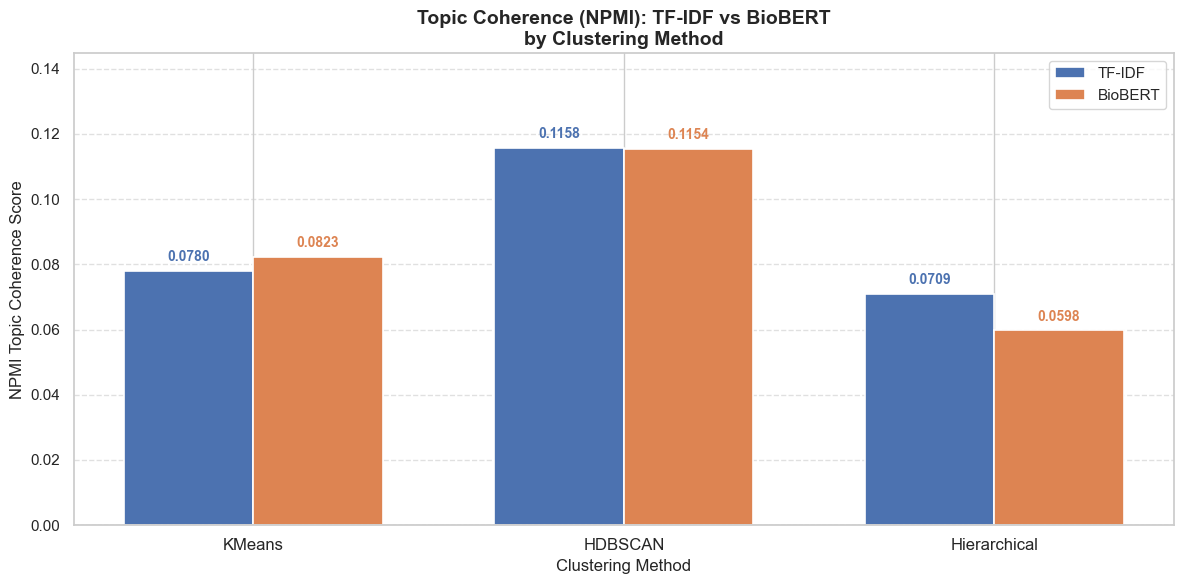

Saved: coherence_grouped_bar.png


In [8]:
print("\n=== STEP 6a: Grouped Bar Chart ===")

methods   = ['KMeans', 'HDBSCAN', 'Hierarchical']
x         = np.arange(len(methods))
bar_width = 0.35

def get_score(pipeline, method):
    row = coherence_df[(coherence_df['Pipeline']==pipeline) & (coherence_df['Method']==method)]
    return row['NPMI_Coherence'].values[0] if len(row) else np.nan

tfidf_scores = [get_score('TF-IDF',  m) for m in methods]
bert_scores  = [get_score('BioBERT', m) for m in methods]

fig, ax = plt.subplots(figsize=(12, 6))
bars1 = ax.bar(x - bar_width/2, tfidf_scores,  bar_width,
               label='TF-IDF',  color='#4C72B0', edgecolor='white', linewidth=1.2)
bars2 = ax.bar(x + bar_width/2, bert_scores,   bar_width,
               label='BioBERT', color='#DD8452', edgecolor='white', linewidth=1.2)

for bar in bars1:
    h = bar.get_height()
    if not np.isnan(h):
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.002,
                f'{h:.4f}', ha='center', va='bottom', fontsize=10,
                fontweight='bold', color='#4C72B0')

for bar in bars2:
    h = bar.get_height()
    if not np.isnan(h):
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.002,
                f'{h:.4f}', ha='center', va='bottom', fontsize=10,
                fontweight='bold', color='#DD8452')

all_vals = [v for v in tfidf_scores + bert_scores if not np.isnan(v)]
ax.set_ylim(0, max(all_vals) * 1.25 if all_vals else 1.0)
ax.set_xticks(x)
ax.set_xticklabels(methods, fontsize=12)
ax.set_ylabel('NPMI Topic Coherence Score', fontsize=12)
ax.set_xlabel('Clustering Method', fontsize=12)
ax.set_title('Topic Coherence (NPMI): TF-IDF vs BioBERT\nby Clustering Method',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.yaxis.grid(True, linestyle='--', alpha=0.6)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(os.path.join(RES_OUT, 'coherence_grouped_bar.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Saved: coherence_grouped_bar.png")


### Per-Topic Coherence Box Plot


=== STEP 6b: Per-Topic Box Plot ===


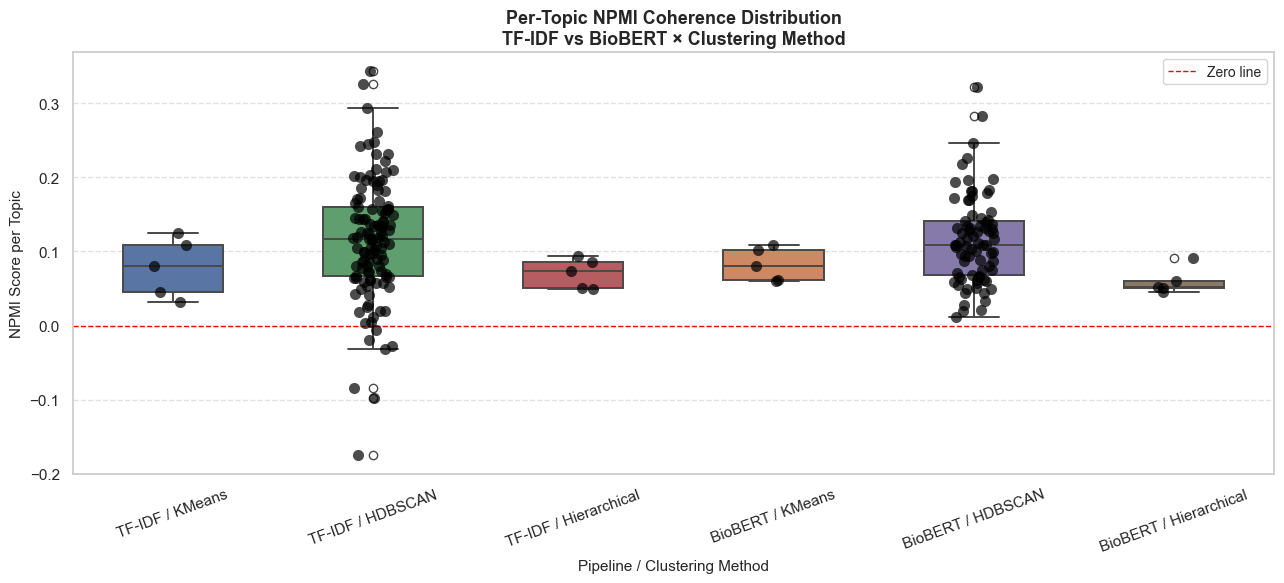

Saved: coherence_per_topic_boxplot.png


In [9]:
print("\n=== STEP 6b: Per-Topic Box Plot ===")

per_topic_df['Group'] = per_topic_df['Pipeline'] + ' / ' + per_topic_df['Method']

palette = {
    'TF-IDF / KMeans':        '#4C72B0',
    'TF-IDF / HDBSCAN':       '#55A868',
    'TF-IDF / Hierarchical':  '#C44E52',
    'BioBERT / KMeans':       '#DD8452',
    'BioBERT / HDBSCAN':      '#8172B2',
    'BioBERT / Hierarchical': '#937860',
}
order  = list(palette.keys())
present = [g for g in order if g in per_topic_df['Group'].unique()]

fig, ax = plt.subplots(figsize=(13, 6))
sns.boxplot(
    data=per_topic_df.dropna(subset=['NPMI_Coherence']),
    x='Group', y='NPMI_Coherence',
    order=present,
    palette={g: palette.get(g, 'gray') for g in present},
    width=0.5, linewidth=1.4, ax=ax
)
sns.stripplot(
    data=per_topic_df.dropna(subset=['NPMI_Coherence']),
    x='Group', y='NPMI_Coherence',
    order=present,
    color='black', size=8, alpha=0.7, jitter=True, ax=ax
)

ax.axhline(0, color='red', linewidth=1, linestyle='--', label='Zero line')
ax.set_title('Per-Topic NPMI Coherence Distribution\nTF-IDF vs BioBERT × Clustering Method',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Pipeline / Clustering Method', fontsize=11)
ax.set_ylabel('NPMI Score per Topic', fontsize=11)
ax.tick_params(axis='x', rotation=20)
ax.yaxis.grid(True, linestyle='--', alpha=0.6)
ax.set_axisbelow(True)
ax.legend(fontsize=10)

plt.tight_layout()
plt.savefig(os.path.join(RES_OUT, 'coherence_per_topic_boxplot.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Saved: coherence_per_topic_boxplot.png")


### Heatmap: Per-Cluster Coherence Score


=== STEP 6c: Per-Cluster Coherence Heatmap ===


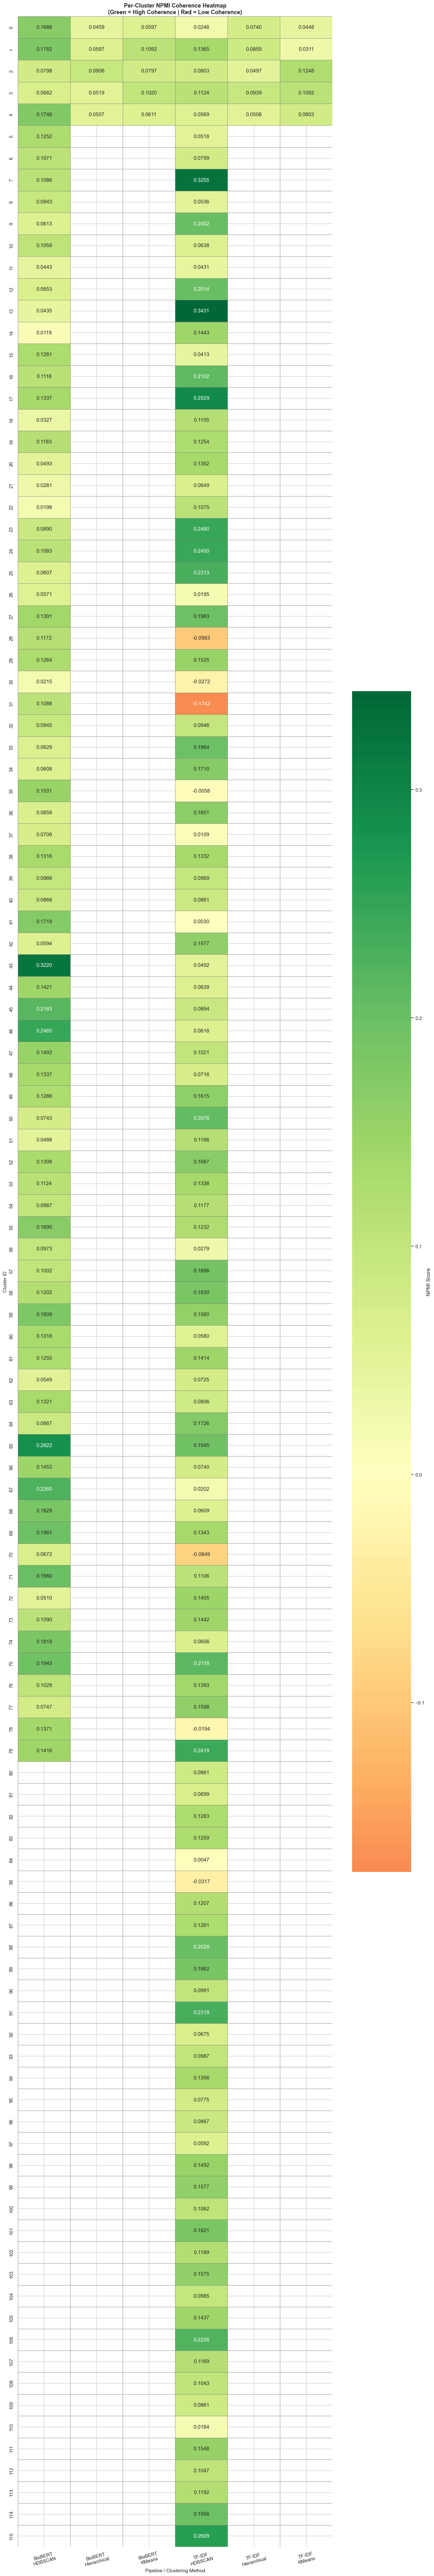

Saved: coherence_heatmap.png


In [10]:
print("\n=== STEP 6c: Per-Cluster Coherence Heatmap ===")

heatmap_data = per_topic_df.copy()
heatmap_data['Config'] = heatmap_data['Pipeline'] + '\n' + heatmap_data['Method']
pivot = heatmap_data.pivot_table(
    index='Cluster',
    columns='Config',
    values='NPMI_Coherence',
    aggfunc='first'
)

fig, ax = plt.subplots(figsize=(14, max(4, len(pivot) * 0.7 + 1)))
sns.heatmap(
    pivot,
    annot=True, fmt='.4f',
    cmap='RdYlGn', center=0,
    linewidths=0.5, linecolor='gray',
    ax=ax,
    cbar_kws={'label': 'NPMI Score'}
)
ax.set_title('Per-Cluster NPMI Coherence Heatmap\n(Green = High Coherence | Red = Low Coherence)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Pipeline / Clustering Method', fontsize=11)
ax.set_ylabel('Cluster ID', fontsize=11)
ax.tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.savefig(os.path.join(RES_OUT, 'coherence_heatmap.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Saved: coherence_heatmap.png")


### Combined Metrics Summary Table (Visual)


=== STEP 6d: Combined Metrics Table ===


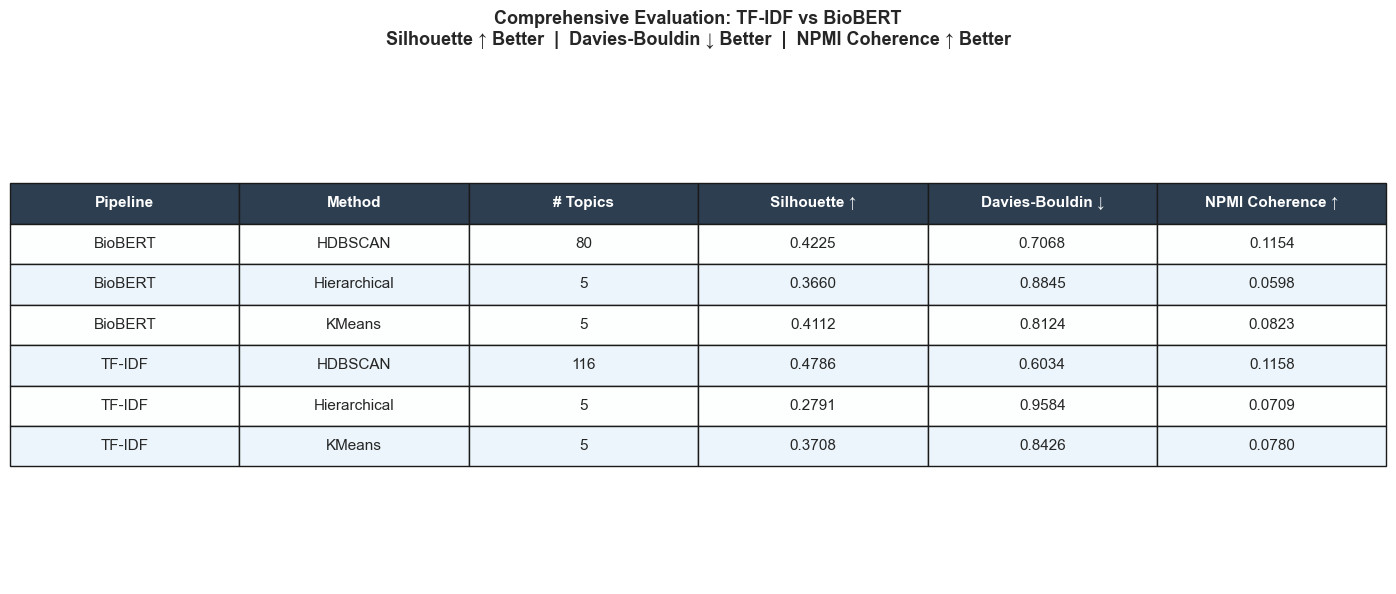

Saved: combined_metrics_table.png


In [11]:
print("\n=== STEP 6d: Combined Metrics Table ===")

fig, ax = plt.subplots(figsize=(14, combined.shape[0] * 0.6 + 2.5))
ax.axis('off')

col_labels = ['Pipeline', 'Method', '# Topics', 'Silhouette ↑', 'Davies-Bouldin ↓', 'NPMI Coherence ↑']

cell_data = []
for _, row in combined.iterrows():
    cell_data.append([
        row['Pipeline'],
        row['Method'],
        str(int(row['Num_Topics'])) if not pd.isna(row['Num_Topics']) else 'N/A',
        f"{row['Silhouette']:.4f}"       if not pd.isna(row['Silhouette'])       else 'N/A',
        f"{row['Davies_Bouldin']:.4f}"   if not pd.isna(row['Davies_Bouldin'])   else 'N/A',
        f"{row['NPMI_Coherence']:.4f}"   if not pd.isna(row['NPMI_Coherence'])   else 'N/A',
    ])

tbl = ax.table(
    cellText=cell_data,
    colLabels=col_labels,
    loc='center',
    cellLoc='center'
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(11)
tbl.scale(1.2, 2.2)

for j in range(len(col_labels)):
    tbl[(0, j)].set_facecolor('#2C3E50')
    tbl[(0, j)].set_text_props(color='white', fontweight='bold')

for i in range(1, len(cell_data) + 1):
    bg = '#EBF5FB' if i % 2 == 0 else '#FDFEFE'
    for j in range(len(col_labels)):
        tbl[(i, j)].set_facecolor(bg)

plt.title(
    'Comprehensive Evaluation: TF-IDF vs BioBERT\n'
    'Silhouette ↑ Better  |  Davies-Bouldin ↓ Better  |  NPMI Coherence ↑ Better',
    fontsize=13, fontweight='bold', pad=15
)
plt.tight_layout()
plt.savefig(os.path.join(RES_OUT, 'combined_metrics_table.png'), dpi=150, bbox_inches='tight')
plt.show()
print("Saved: combined_metrics_table.png")


## Step 7: Interpretation & Final Summary

In [12]:
print("\n" + "="*70)
print("  NPMI TOPIC COHERENCE — INTERPRETATION GUIDE")
print("="*70)
print("  Range: -1.0 → +1.0  (higher = more coherent, semantically consistent topics)")
print("  Typical thresholds for domain-specific corpora:")
print("    < 0.00  → Poor:     topic words rarely co-occur (noisy/meaningless topics)")
print("    0.00–0.05 → Fair:   weak but detectable co-occurrence")
print("    0.05–0.15 → Good:   solid semantic coherence")
print("    > 0.15  → Excellent: highly consistent, domain-specific topics")
print("="*70)

valid_rows = coherence_df.dropna(subset=['NPMI_Coherence'])
if not valid_rows.empty:
    best  = valid_rows.loc[valid_rows['NPMI_Coherence'].idxmax()]
    worst = valid_rows.loc[valid_rows['NPMI_Coherence'].idxmin()]
    print(f"\n  🏆 Best  → {best['Pipeline']} / {best['Method']}: NPMI = {best['NPMI_Coherence']:.4f}")
    print(f"  ⚠️  Worst → {worst['Pipeline']} / {worst['Method']}: NPMI = {worst['NPMI_Coherence']:.4f}")

    tfidf_mean = coherence_df[coherence_df['Pipeline']=='TF-IDF']['NPMI_Coherence'].mean()
    bert_mean  = coherence_df[coherence_df['Pipeline']=='BioBERT']['NPMI_Coherence'].mean()
    print(f"\n  TF-IDF  mean NPMI (across all methods): {tfidf_mean:.4f}")
    print(f"  BioBERT mean NPMI (across all methods): {bert_mean:.4f}")
    winner = 'BioBERT' if bert_mean > tfidf_mean else 'TF-IDF'
    diff   = abs(bert_mean - tfidf_mean)
    print(f"\n  → {winner} produces more coherent topics on average (Δ = {diff:.4f}).")

    # Best clustering method
    for method in ['KMeans', 'HDBSCAN', 'Hierarchical']:
        subset = coherence_df[coherence_df['Method']==method]['NPMI_Coherence']
        print(f"  {method:15s} mean NPMI: {subset.mean():.4f}")

print(f"\n✅ All results saved to: '{RES_OUT}/'")
print("   • topic_coherence_summary.csv")
print("   • topic_coherence_per_topic.csv")
print("   • combined_evaluation_metrics.csv")
print("   • coherence_grouped_bar.png")
print("   • coherence_per_topic_boxplot.png")
print("   • coherence_heatmap.png")
print("   • combined_metrics_table.png")



  NPMI TOPIC COHERENCE — INTERPRETATION GUIDE
  Range: -1.0 → +1.0  (higher = more coherent, semantically consistent topics)
  Typical thresholds for domain-specific corpora:
    < 0.00  → Poor:     topic words rarely co-occur (noisy/meaningless topics)
    0.00–0.05 → Fair:   weak but detectable co-occurrence
    0.05–0.15 → Good:   solid semantic coherence
    > 0.15  → Excellent: highly consistent, domain-specific topics

  🏆 Best  → TF-IDF / HDBSCAN: NPMI = 0.1158
  ⚠️  Worst → BioBERT / Hierarchical: NPMI = 0.0598

  TF-IDF  mean NPMI (across all methods): 0.0882
  BioBERT mean NPMI (across all methods): 0.0858

  → TF-IDF produces more coherent topics on average (Δ = 0.0024).
  KMeans          mean NPMI: 0.0801
  HDBSCAN         mean NPMI: 0.1156
  Hierarchical    mean NPMI: 0.0654

✅ All results saved to: 'Coherence Results/'
   • topic_coherence_summary.csv
   • topic_coherence_per_topic.csv
   • combined_evaluation_metrics.csv
   • coherence_grouped_bar.png
   • coherence_per